<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/05_ML_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multilayer Perceptron (MLP)


---


Multilayer perceptron (MLP) networks are one of the most commonly used networks, they are also considered as feed-forward networks. The development of the back-propagation learning algorithm for determining weights was the main reason behind the popularity of these networks among researchers. As the name suggests, an MLP consists of multiple perceptrons arranged into a number of layers in order to deal with complex problems. A typical MLP consists of an input layer, hidden layer(s) and an output layer. The units (neurons) in each layer are fully connected to the following layer. MLPs are usually described according to the number of neurons and layers used. For example, a 3-5-4 MLP is a two-layer network consisting of an input layer with three inputs, a hidden layer with five neurons and an output layer with four outputs. The figure below represent a 4-layer MLP (Note: the input layer is not counted as a layer).


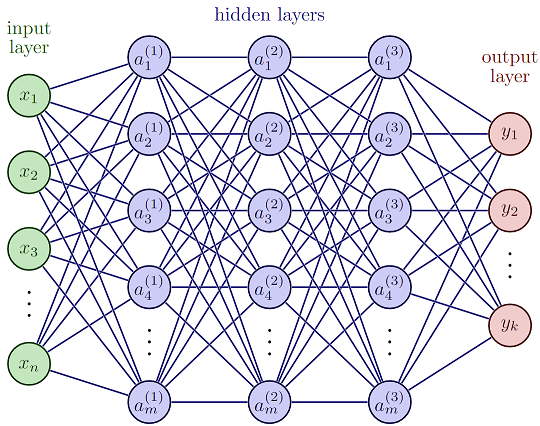

The feedforward operation is shown in the diagram below. Each neuron multiplies its inputs $a$ with corresponding weights $w$. The activation function $\theta$ is used to add non-linearity to the process and allows it to learn complex data sets (the network is equivalent to one linear transformation without these non-linearities - try to show this!). The activation function is applied after multiplying the weights with the inputs and summing the results.


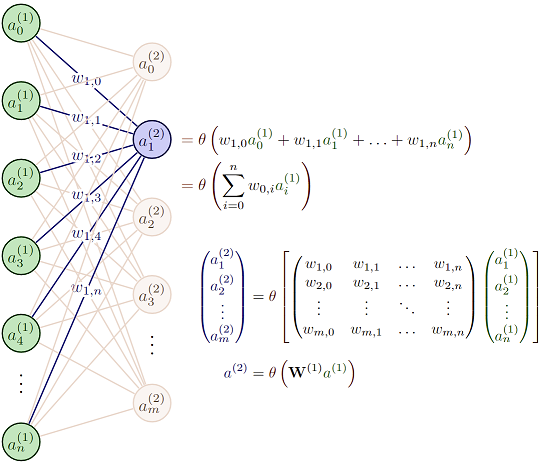

Many activation functions can be used in MLP depending on the problem being investigated. In the figure below are some examples of common activation functions.

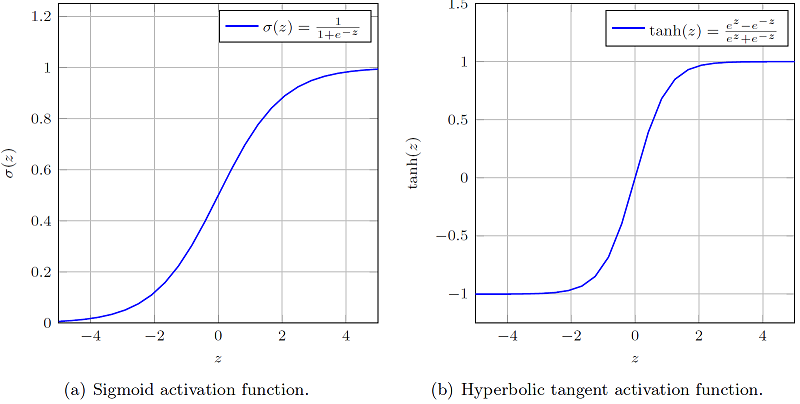

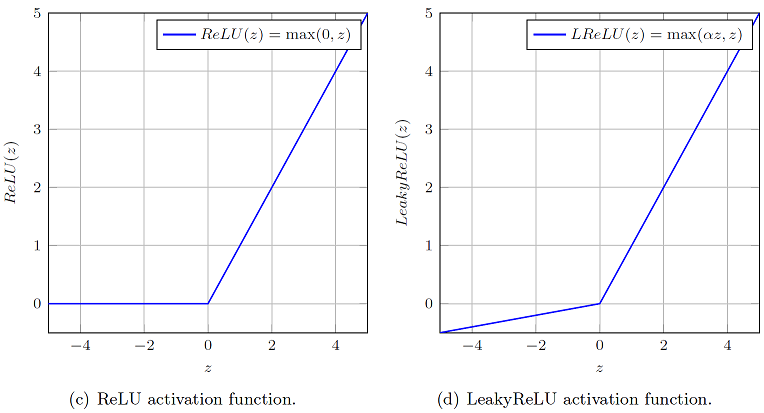

Many forms of cost functions $J$ to measure the error are available as mentioned in the previous tutorials. The objective of this process is to get the optimal set of tunable parameters (weights and biases) that will minimise the cost $J$. Back-propagation and gradient descent are used to apply these optimisation steps in a systematic manner such that the weights and biases are updated using the derivative and chain-rule concepts as described in the equations below.


\begin{aligned}
    \Delta w_i=-\alpha \frac{\partial J}{\partial w_i} \\
    w_{i}(t+1)=w_i(t)+\Delta w_i
\end{aligned}



The hyperparameter $\alpha$ is called the learning rate which is selected before the training takes place. If the value of $\alpha$ is too high, the algorithm may learn faster; however, it may diverge in reaching the minimal value resulting in oscillating behaviour. On the other hand, if the value of $\alpha$ is too small, the learning process will be slow but more stable. Parameter $t$ refers to the number of iterations (equivalent to number of epochs if update is calculated over entire dataset) where the weights are updated. At the start of training, the weights are usually given random values.






# MNIST Dataset

In this notebook, we will use a common open access dataset called Modified National Institute of Standards and Technology (MNIST) shown in Figure below.

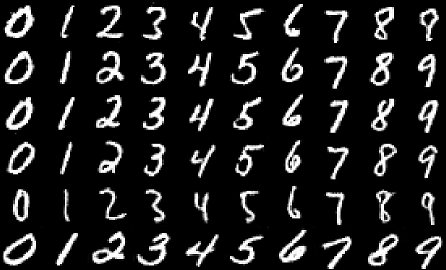


This data contains 70,000 scanned images of handwritten digits, together with their correct labels. These images are scanned handwriting samples from 250 people, half of whom were US Census Bureau employees, and the other half were high school students. The images are in grayscale format and of size $28\times 28$ pixels each. The labels are in integer format such that each image has the correct corresponding label that describes it as a number from 0 to 9. The MNIST data is divided into two parts. The first part is the training data that contains 60,000 images. The second part is the test data that contains 10,000 images.

## The code below is from "Python Machine Learning," Sebastian Raschka, Packt Publishing, 2015 (page 356), with modifications.

In [1]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import sys
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Importing the data from tensoflow library into train and test.
(X_train, y_train), (X_test, y_test) = mnist.load_data()

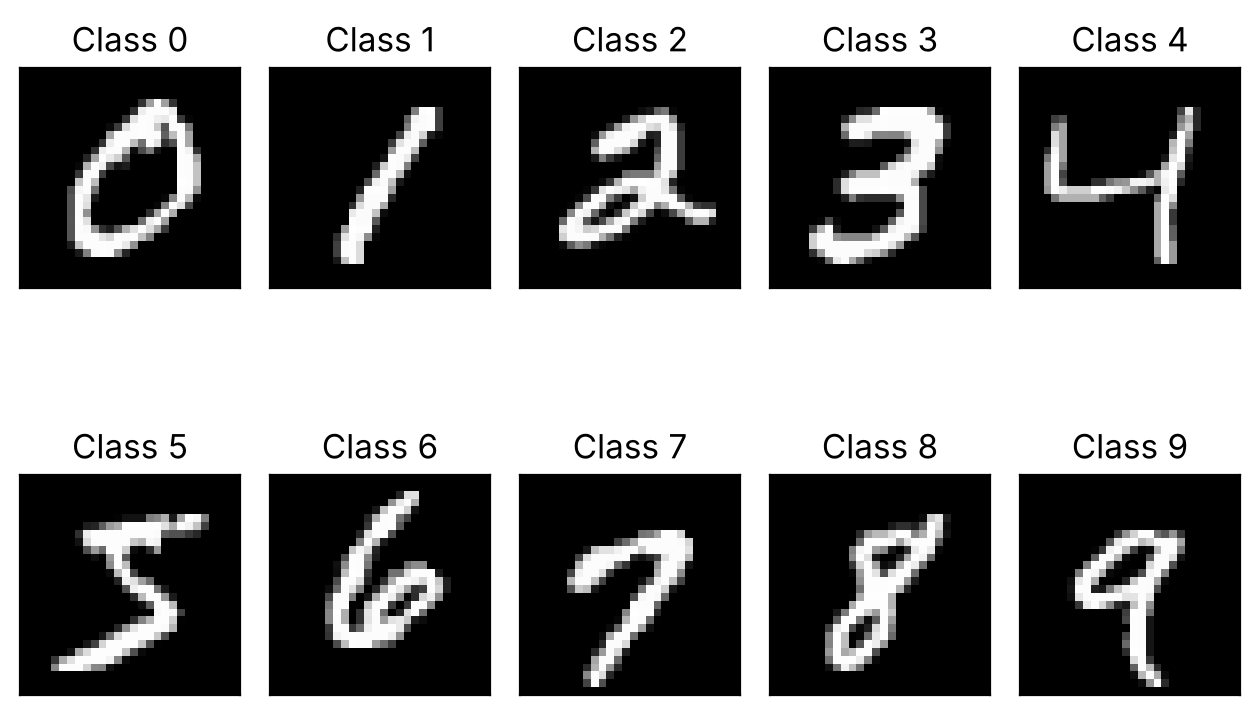

In [3]:
# Displaying samples of the 10 classes in this data

fig = plt.figure()
for i in range(10):
    plt.subplot(2, 5, i+1)
    x_y = X_train[y_train == i]
    plt.imshow(x_y[0], cmap='gray', interpolation='none')
    plt.title("Class %d" % (i))
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()

Samples of class 3:


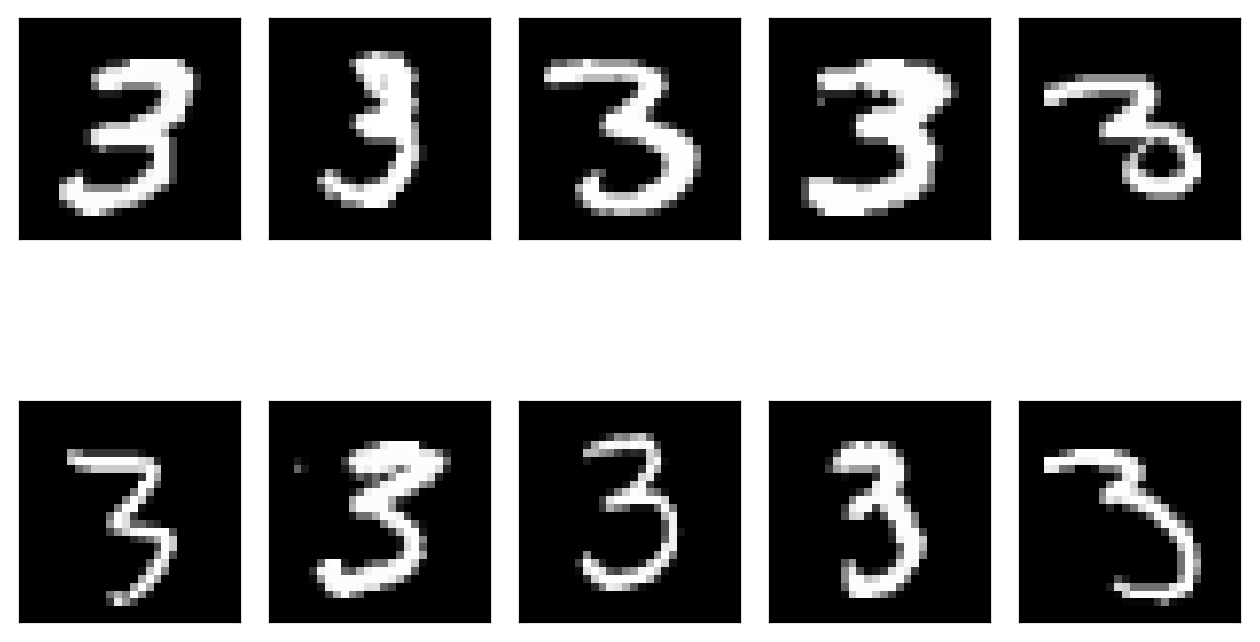

In [4]:
# Displaying different samples of the same class.
print("Samples of class 3:")
fig = plt.figure()

for i in range(10):
    plt.subplot(2, 5, i+1)
    x_y = X_train[y_train == 3]
    plt.imshow(x_y[i], cmap='gray', interpolation='none')
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()

Before the images are fed to the MLP, they should go through simple pre-processing steps. First, the pixel values are scaled (normalised) to have values between 0 and 1. In order to do that, all the pixel values are divided by 255 (MNIST grayscale images have 256 different gray values, numbered 0 - 255 (8 bits)). This improves learning stability. Secondly, the image should be flattened to a vector format as the MLP takes a vector with each input corresponding to a pixel location.

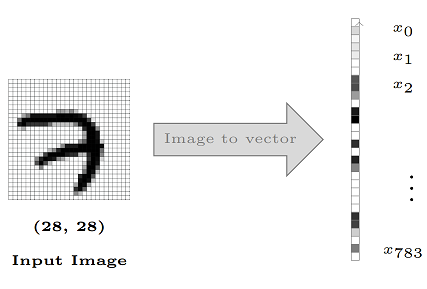

In [5]:
print('X_train.shape', X_train.shape)
print('X_test.shape', X_test.shape)
# reshaping the inputs
X_train = X_train.reshape(60000, 28*28)
X_test = X_test.reshape(10000, 28*28)
# normalizing the inputs (-1, 1)
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
print('X_train reshape:', X_train.shape)
print('X_test reshape:', X_test.shape)

X_train.shape (60000, 28, 28)
X_test.shape (10000, 28, 28)


X_train reshape: (60000, 784)
X_test reshape: (10000, 784)


In [6]:
# Create a random permutation of indices
num_train_samples = len(X_train)
num_test_samples = len(X_test)

train_indices = np.random.permutation(num_train_samples)
test_indices = np.random.permutation(num_test_samples)

# Shuffle the data using the permutation of indices
X_train = X_train[train_indices]
y_train = y_train[train_indices]

X_test = X_test[test_indices]
y_test = y_test[test_indices]

The MNIST data does not include validation dataset; however, we can use part of the training set for validation as follows:

In [7]:
X_valid=X_train[:5000]
y_valid=y_train[:5000]
X_train=X_train[5000:60000]
y_train=y_train[5000:60000]


In [8]:
class NeuralNetMLP(object):
    """ Feedforward neural network / Multi-layer perceptron classifier.

    Parameters
    ------------
    n_hidden : int (default: 30)
        Number of hidden units.
    l2 : float (default: 0.)
        Lambda value for L2-regularization.
        No regularization if l2=0. (default)
    epochs : int (default: 100)
        Number of passes over the training set.
    alpha : float (default: 0.001)
        Learning rate.
    shuffle : bool (default: True)
        Shuffles training data every epoch if True to prevent circles.
    minibatch_size : int (default: 1)
        Number of training examples per minibatch.
    seed : int (default: None)
        Random seed for initializing weights and shuffling.

    Attributes
    -----------
    eval_ : dict
      Dictionary collecting the cost, training accuracy,
      and validation accuracy for each epoch during training.

    """
    def __init__(self, n_hidden=30,
                 l2=0., epochs=100, alpha=0.001,
                 shuffle=True, minibatch_size=1, seed=None,
                 activation="sigmoid"):

        self.random = np.random.RandomState(seed)
        self.n_hidden = n_hidden
        self.l2 = l2
        self.epochs = epochs
        self.alpha = alpha
        self.shuffle = shuffle
        self.minibatch_size = minibatch_size
        if activation == "sigmoid":
            self.act = self._sigmoid
            self.act_deriv = lambda a_h: a_h * (1. - a_h)

        ##########################################################################
        #### Task 1 (Part B): other hidden-layer activation functions.
        #### act_deriv receives the *activation* a_h (as in the sigmoid case), so
        #### each derivative is written in terms of a_h.
        ##########################################################################
        elif activation == "tanh":
            self.act = np.tanh
            self.act_deriv = lambda a_h: 1. - a_h ** 2               # d/dz tanh(z) = 1 - tanh(z)^2
        elif activation == "relu":
            self.act = lambda z: np.maximum(0., z)
            self.act_deriv = lambda a_h: (a_h > 0.).astype(float)    # 1 if z > 0 else 0
        else:
            raise ValueError("activation must be 'sigmoid', 'tanh' or 'relu'")



    def _onehot(self, y, n_classes):
        """Encode labels into one-hot representation

        Parameters
        ------------
        y : array, shape = [n_examples]
            Target values.
        n_classes : int
            Number of classes

        Returns
        -----------
        onehot : array, shape = (n_examples, n_labels)

        """
        onehot = np.zeros((n_classes, y.shape[0]))
        for idx, val in enumerate(y.astype(int)):
            onehot[val, idx] = 1.
        return onehot.T

    def _sigmoid(self, z):
        """Compute logistic function (sigmoid)"""
        return 1. / (1. + np.exp(-np.clip(z, -250, 250)))

    def _forward(self, X):
        """Compute forward propagation step"""

        # step 1: net input of hidden layer
        # [n_examples, n_features] dot [n_features, n_hidden]
        # -> [n_examples, n_hidden]
        z_h = np.dot(X, self.w_h) + self.b_h

        # step 2: activation of hidden layer
        a_h = self.act(z_h)

        # step 3: net input of output layer
        # [n_examples, n_hidden] dot [n_hidden, n_classlabels]
        # -> [n_examples, n_classlabels]

        z_out = np.dot(a_h, self.w_out) + self.b_out

        # step 4: activation output layer
        a_out = self._sigmoid(z_out)

        return z_h, a_h, z_out, a_out

    def _compute_cost(self, y_enc, output):
        """Compute cost function.

        Parameters
        ----------
        y_enc : array, shape = (n_examples, n_labels)
            one-hot encoded class labels.
        output : array, shape = [n_examples, n_output_units]
            Activation of the output layer (forward propagation)

        Returns
        ---------
        cost : float
            Regularized cost

        """
        L2_term = (self.l2 *
                   (np.sum(self.w_h ** 2.) +
                    np.sum(self.w_out ** 2.)))

        term1 = -y_enc * (np.log(output))
        term2 = (1. - y_enc) * np.log(1. - output)
        cost = np.sum(term1 - term2) + L2_term

        # If you are applying this cost function to other
        # datasets where activation
        # values maybe become more extreme (closer to zero or 1)
        # you may encounter "ZeroDivisionError"s due to numerical
        # instabilities in Python & NumPy for the current implementation.
        # I.e., the code tries to evaluate log(0), which is undefined.
        # To address this issue, you could add a small constant to the
        # activation values that are passed to the log function.
        #
        # For example:
        #
        # term1 = -y_enc * (np.log(output + 1e-5))
        # term2 = (1. - y_enc) * np.log(1. - output + 1e-5)

        return cost

    def predict(self, X):
        """Predict class labels

        Parameters
        -----------
        X : array, shape = [n_examples, n_features]
            Input layer with original features.

        Returns:
        ----------
        y_pred : array, shape = [n_examples]
            Predicted class labels.

        """
        z_h, a_h, z_out, a_out = self._forward(X)
        y_pred = np.argmax(z_out, axis=1)
        return y_pred

    def fit(self, X_train, y_train, X_valid, y_valid):
        """ Learn weights from training data.

        Parameters
        -----------
        X_train : array, shape = [n_examples, n_features]
            Input layer with original features.
        y_train : array, shape = [n_examples]
            Target class labels.
        X_valid : array, shape = [n_examples, n_features]
            Sample features for validation during training
        y_valid : array, shape = [n_examples]
            Sample labels for validation during training

        Returns:
        ----------
        self

        """
        n_output = np.unique(y_train).shape[0]  # number of class labels
        n_features = X_train.shape[1]

        ########################
        # Weight initialization
        ########################

        # weights for input -> hidden
        self.b_h = np.zeros(self.n_hidden)
        self.w_h = self.random.normal(loc=0.0, scale=0.1,
                                      size=(n_features, self.n_hidden))

        # weights for hidden -> output
        self.b_out = np.zeros(n_output)
        self.w_out = self.random.normal(loc=0.0, scale=0.1,
                                        size=(self.n_hidden, n_output))

        epoch_strlen = len(str(self.epochs))  # for progress formatting
        self.eval_ = {'cost': [], 'train_acc': [], 'valid_acc': []}

        y_train_enc = self._onehot(y_train, n_output)

        # iterate over training epochs
        for i in range(self.epochs):

            # iterate over minibatches
            indices = np.arange(X_train.shape[0])

            if self.shuffle:
                self.random.shuffle(indices)

            for start_idx in range(0, indices.shape[0] - self.minibatch_size +
                                   1, self.minibatch_size):
                batch_idx = indices[start_idx:start_idx + self.minibatch_size]

                # forward propagation
                z_h, a_h, z_out, a_out = self._forward(X_train[batch_idx])

                ##################
                # Backpropagation
                ##################

                # [n_examples, n_classlabels]
                delta_out = a_out - y_train_enc[batch_idx]

                # [n_examples, n_hidden]
                act_derivative_h = self.act_deriv(a_h)

                # [n_examples, n_classlabels] dot [n_classlabels, n_hidden]
                # -> [n_examples, n_hidden]
                delta_h = (np.dot(delta_out, self.w_out.T) *
                           act_derivative_h)

                # [n_features, n_examples] dot [n_examples, n_hidden]
                # -> [n_features, n_hidden]
                grad_w_h = np.dot(X_train[batch_idx].T, delta_h)
                grad_b_h = np.sum(delta_h, axis=0)

                # [n_hidden, n_examples] dot [n_examples, n_classlabels]
                # -> [n_hidden, n_classlabels]
                grad_w_out = np.dot(a_h.T, delta_out)
                grad_b_out = np.sum(delta_out, axis=0)

                # Regularization and weight updates
                delta_w_h = (grad_w_h + self.l2*self.w_h)
                delta_b_h = grad_b_h # bias is not regularized
                self.w_h -= self.alpha * delta_w_h
                self.b_h -= self.alpha * delta_b_h

                delta_w_out = (grad_w_out + self.l2*self.w_out)
                delta_b_out = grad_b_out  # bias is not regularized
                self.w_out -= self.alpha * delta_w_out
                self.b_out -= self.alpha * delta_b_out

            #############
            # Evaluation
            #############

            # Evaluation after each epoch during training
            z_h, a_h, z_out, a_out = self._forward(X_train)

            cost = self._compute_cost(y_enc=y_train_enc,
                                      output=a_out)

            y_train_pred = self.predict(X_train)
            y_valid_pred = self.predict(X_valid)

            train_acc = ((np.sum(y_train == y_train_pred)).astype(float) /
                         X_train.shape[0])
            valid_acc = ((np.sum(y_valid == y_valid_pred)).astype(float) /
                         X_valid.shape[0])

            print('\r%0*d/%d | Cost: %.2f '
                  '| Train/Valid Acc.: %.2f%%/%.2f%% ' %
                  (epoch_strlen, i+1, self.epochs, cost,
                  train_acc*100, valid_acc*100))
            # sys.stderr.write
            # sys.stderr.flush()

            self.eval_['cost'].append(cost)
            self.eval_['train_acc'].append(train_acc)
            self.eval_['valid_acc'].append(valid_acc)

        return self

In [9]:
# Executing the algorithm here (it may take some time to execute the code)

n_epochs = 200 # Number of training epochs

# Initialize a NeuralNet MLP
nn = NeuralNetMLP(
    n_hidden=100,
    l2=10,
    epochs=n_epochs,
    alpha=0.0005,
    minibatch_size=100,
    shuffle=True,
    seed=1,
    activation="sigmoid"
)

# Here we use part of the training data for validation such that 55000 data samples for training and the rest 5000
#for validation
nn.fit(
    X_train,
    y_train,
    X_valid,
    y_valid
)

001/200 | Cost: 165995.10 | Train/Valid Acc.: 47.33%/47.90% 


002/200 | Cost: 164465.56 | Train/Valid Acc.: 31.61%/31.72% 


003/200 | Cost: 163791.95 | Train/Valid Acc.: 36.51%/36.54% 


004/200 | Cost: 163399.22 | Train/Valid Acc.: 31.59%/31.82% 


005/200 | Cost: 163322.92 | Train/Valid Acc.: 38.89%/38.86% 


006/200 | Cost: 163183.12 | Train/Valid Acc.: 36.23%/35.28% 


... (190 outputs left out)

197/200 | Cost: 161502.15 | Train/Valid Acc.: 39.39%/38.58% 


198/200 | Cost: 161614.80 | Train/Valid Acc.: 36.38%/36.48% 


199/200 | Cost: 161733.39 | Train/Valid Acc.: 38.52%/38.60% 


200/200 | Cost: 161543.38 | Train/Valid Acc.: 37.71%/37.42% 


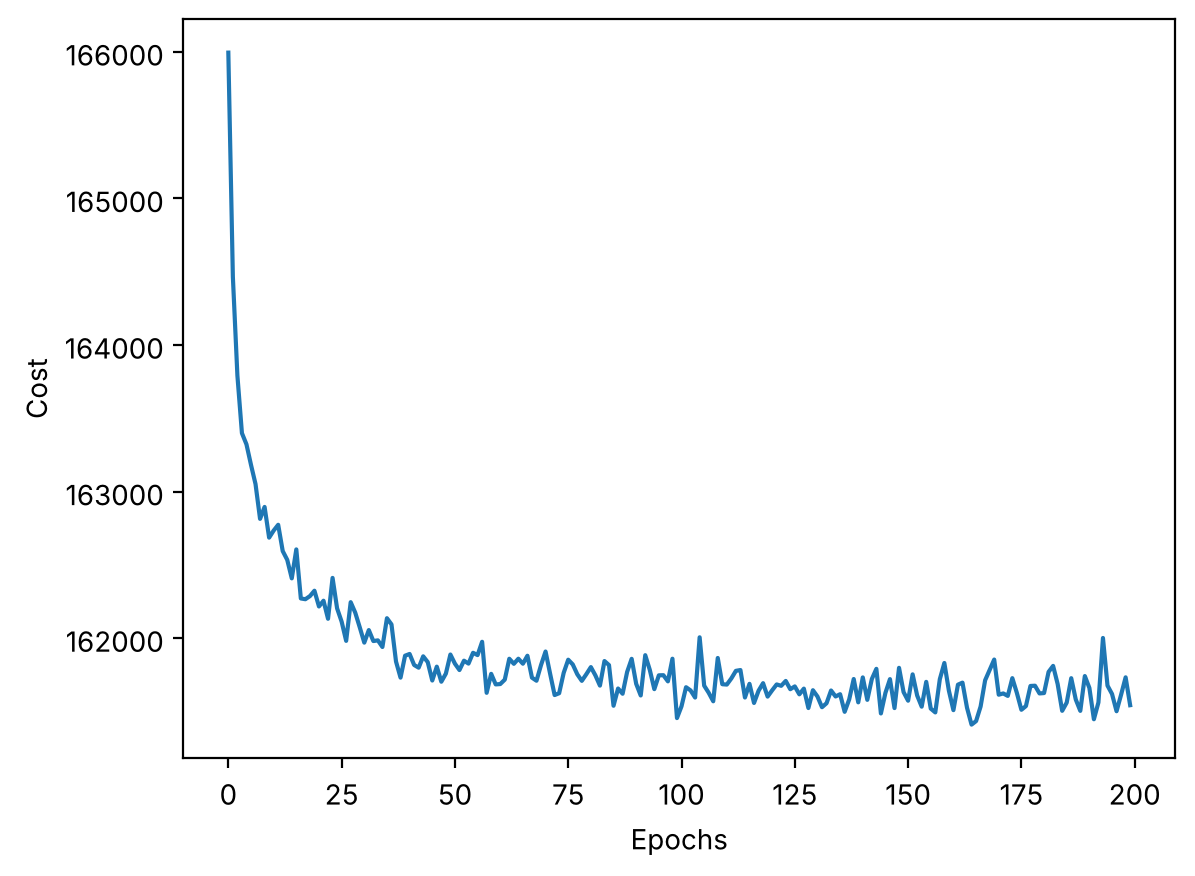

In [10]:
# plot the cost vs epochs
plt.plot(range(nn.epochs), nn.eval_['cost'])
plt.ylabel('Cost')
plt.xlabel('Epochs')
plt.show()

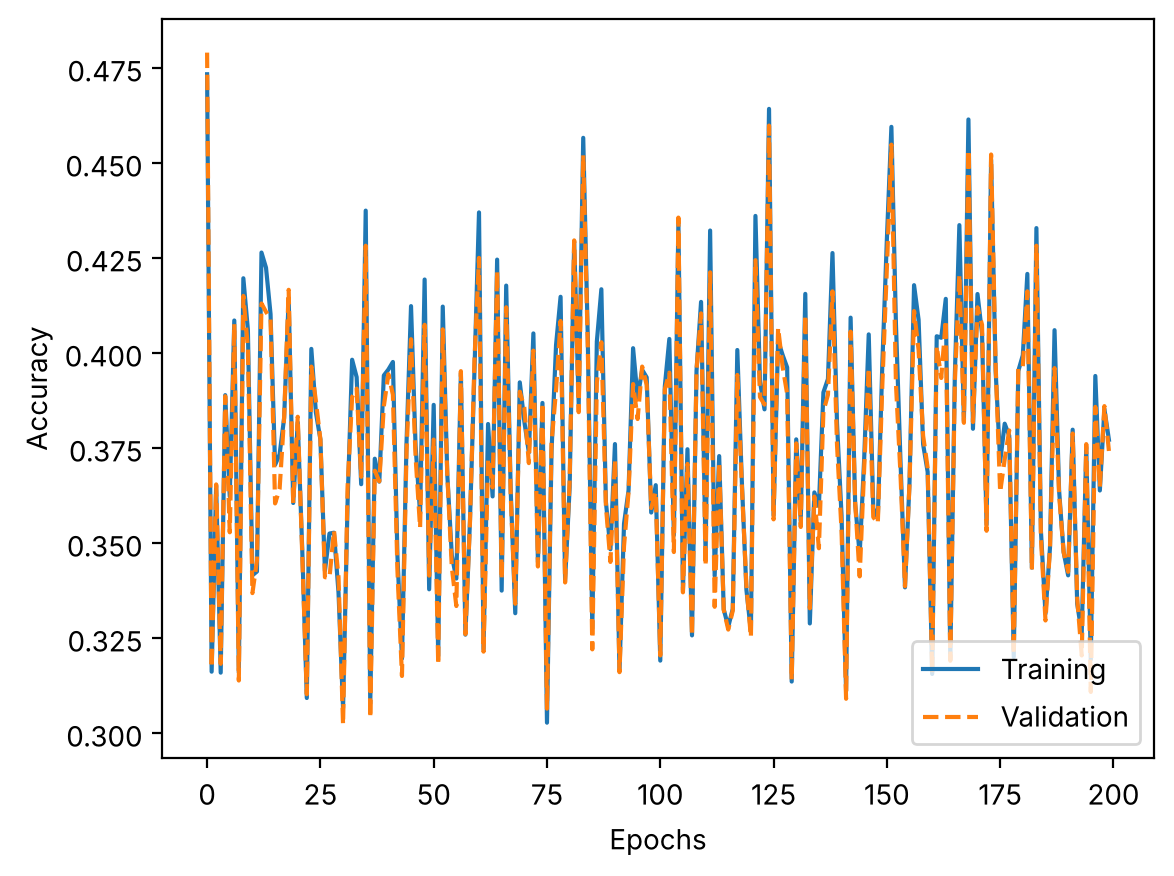

In [11]:
plt.plot(range(nn.epochs), nn.eval_['train_acc'],
         label='Training')
plt.plot(range(nn.epochs), nn.eval_['valid_acc'],
         label='Validation', linestyle='--')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(loc='lower right')
plt.show()

In [12]:
y_test_pred = nn.predict(X_test)
acc = (np.sum(y_test == y_test_pred)
       .astype(float) / X_test.shape[0])

print('Test accuracy: %.2f%%' % (acc * 100))

Test accuracy: 37.29%


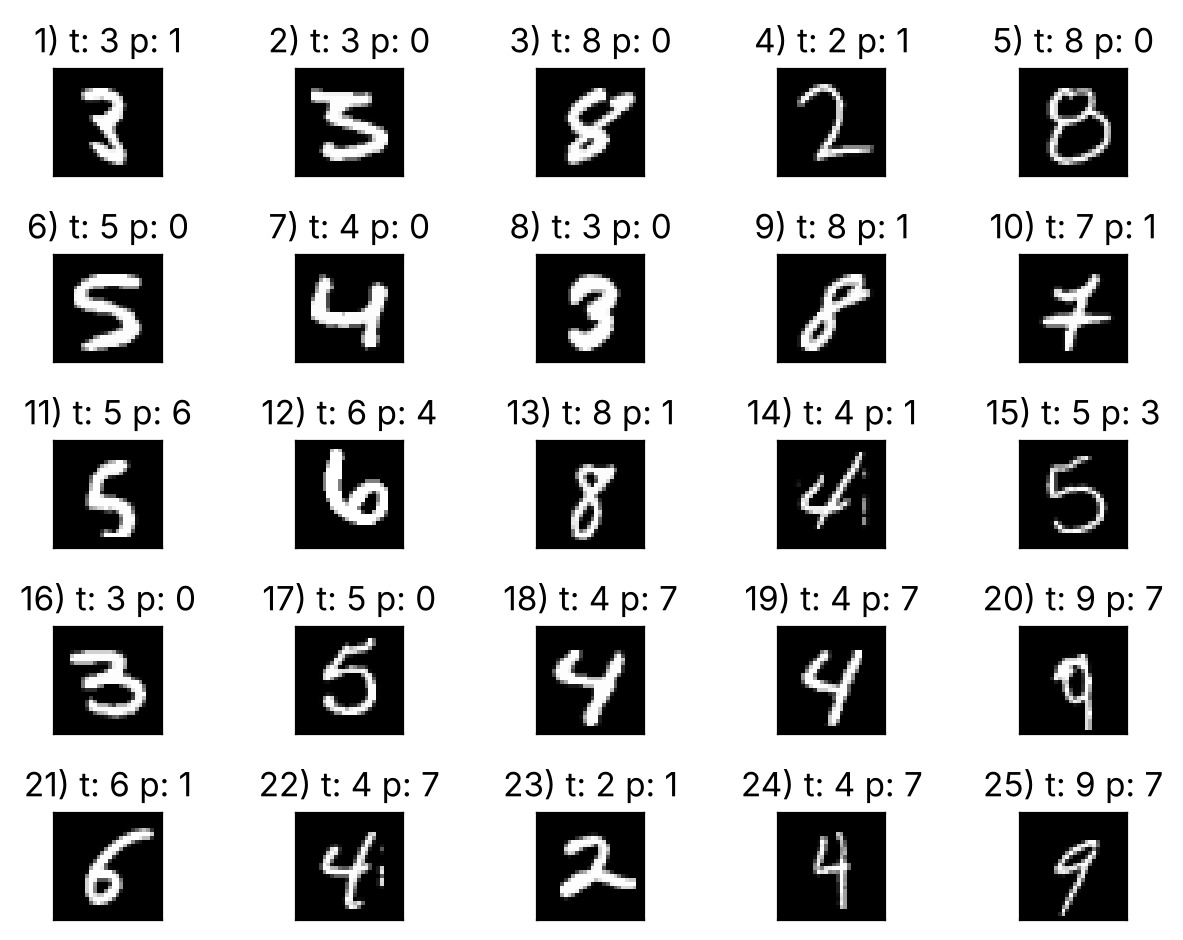

In [13]:
# Plot examples of misclassified images
miscl_img = X_test[y_test != y_test_pred][:25]
correct_lab = y_test[y_test != y_test_pred][:25]
miscl_lab = y_test_pred[y_test != y_test_pred][:25]

fig, ax = plt.subplots(nrows=5, ncols=5, sharex=True, sharey=True)
ax = ax.flatten()
for i in range(25):
    img = miscl_img[i].reshape(28, 28)
    ax[i].imshow(img, cmap='gray', interpolation='nearest')
    ax[i].set_title('%d) t: %d p: %d' % (i+1, correct_lab[i], miscl_lab[i]))

ax[0].set_xticks([])
ax[0].set_yticks([])
plt.tight_layout()
plt.show()

## Task 1 [60 marks]

### Part A: Optimize L2 Regularization

In the provided code, an L2 regularization parameter, `l2`, was set to 10. Your task is to find the close to optimal value for `l2` that can improve the model's performance (this can be done by trial and error and there is no need to perform grid search). After selecting the optimal `l2` value, report the following accuracies:
- Training accuracy
- Validation accuracy
- Test accuracy

Discuss in your report why these accuracies changed significantly when you experimented with different `l2` values. Hint: Try lower values of `l2`.

### Part B: Explore Activation Functions

Modify the code to use different activation functions in the hidden layer, specifically `tanh` and `relu`. Keep the output layer activation function as `sigmoid` since the output needs to be in the range 0-1 for cross-entropy loss calculation. Use the previously optimized `l2` value for this part. Report the effects of using these activation functions on the training, validation, and test accuracies.

Please provide detailed explanations of the observed changes in accuracy and any insights you gain from these experiments.


### Task 1 – Part A: Optimising the L2 regularisation

`l2` values are tried by trial and error from the tutorial value (10) downwards, each a factor of 10 smaller. To keep the run time reasonable, each candidate is trained for a shorter **screening run** (`N_EPOCHS_SCREEN` epochs) with everything else the same as the tutorial (100 hidden units, α = 0.0005, mini-batch 100, seed 1). The best value is then retrained for the full 200 epochs. The per-epoch printout is hidden during screening, and only the final accuracies are shown.

In [14]:
import io, contextlib, time

N_EPOCHS_SCREEN = 50      # screening run for each l2 candidate
N_EPOCHS_FULL = 200       # full run (same as the tutorial)

def train_mlp(l2, activation="sigmoid", epochs=N_EPOCHS_FULL, verbose=True):
    """Train the tutorial MLP with everything fixed except l2 / activation / epochs."""
    model = NeuralNetMLP(n_hidden=100, l2=l2, epochs=epochs, alpha=0.0005,
                         minibatch_size=100, shuffle=True, seed=1, activation=activation)
    t0 = time.time()
    if verbose:
        model.fit(X_train, y_train, X_valid, y_valid)
    else:
        with contextlib.redirect_stdout(io.StringIO()):     # hide the per-epoch printout
            model.fit(X_train, y_train, X_valid, y_valid)
    test_acc = np.mean(model.predict(X_test) == y_test)
    return model, {"activation": activation, "l2": l2, "epochs": epochs,
                   "train_acc (%)": 100 * model.eval_['train_acc'][-1],
                   "valid_acc (%)": 100 * model.eval_['valid_acc'][-1],
                   "test_acc (%)": 100 * test_acc,
                   "time (s)": round(time.time() - t0)}

In [15]:
# Part A - screening different l2 values
import pandas as pd

l2_values = [10, 1, 0.1, 0.01, 0.001]
screen_models, screen_results = {}, []
for l2 in l2_values:
    m, res = train_mlp(l2, "sigmoid", epochs=N_EPOCHS_SCREEN, verbose=False)
    screen_models[l2] = m
    screen_results.append(res)
    print(f"l2 = {l2:<6} train = {res['train_acc (%)']:.2f}%  valid = {res['valid_acc (%)']:.2f}%  "
          f"test = {res['test_acc (%)']:.2f}%  ({res['time (s)']} s)")

screen_df = pd.DataFrame(screen_results)
screen_df.round(2)

l2 = 10     train = 33.78%  valid = 34.14%  test = 33.57%  (118 s)


l2 = 1      train = 88.67%  valid = 88.20%  test = 89.17%  (121 s)


l2 = 0.1    train = 94.25%  valid = 93.62%  test = 94.06%  (117 s)


l2 = 0.01   train = 95.78%  valid = 95.02%  test = 95.47%  (107 s)


l2 = 0.001  train = 95.96%  valid = 95.14%  test = 95.58%  (115 s)


,activation,l2,epochs,train_acc (%),valid_acc (%),test_acc (%),time (s)
0,sigmoid,10.00,50,33.78,34.14,33.57,118
1,sigmoid,1.00,50,88.67,88.20,89.17,121
2,sigmoid,0.10,50,94.25,93.62,94.06,117
3,sigmoid,0.01,50,95.78,95.02,95.47,107
4,sigmoid,0.00,50,95.96,95.14,95.58,115


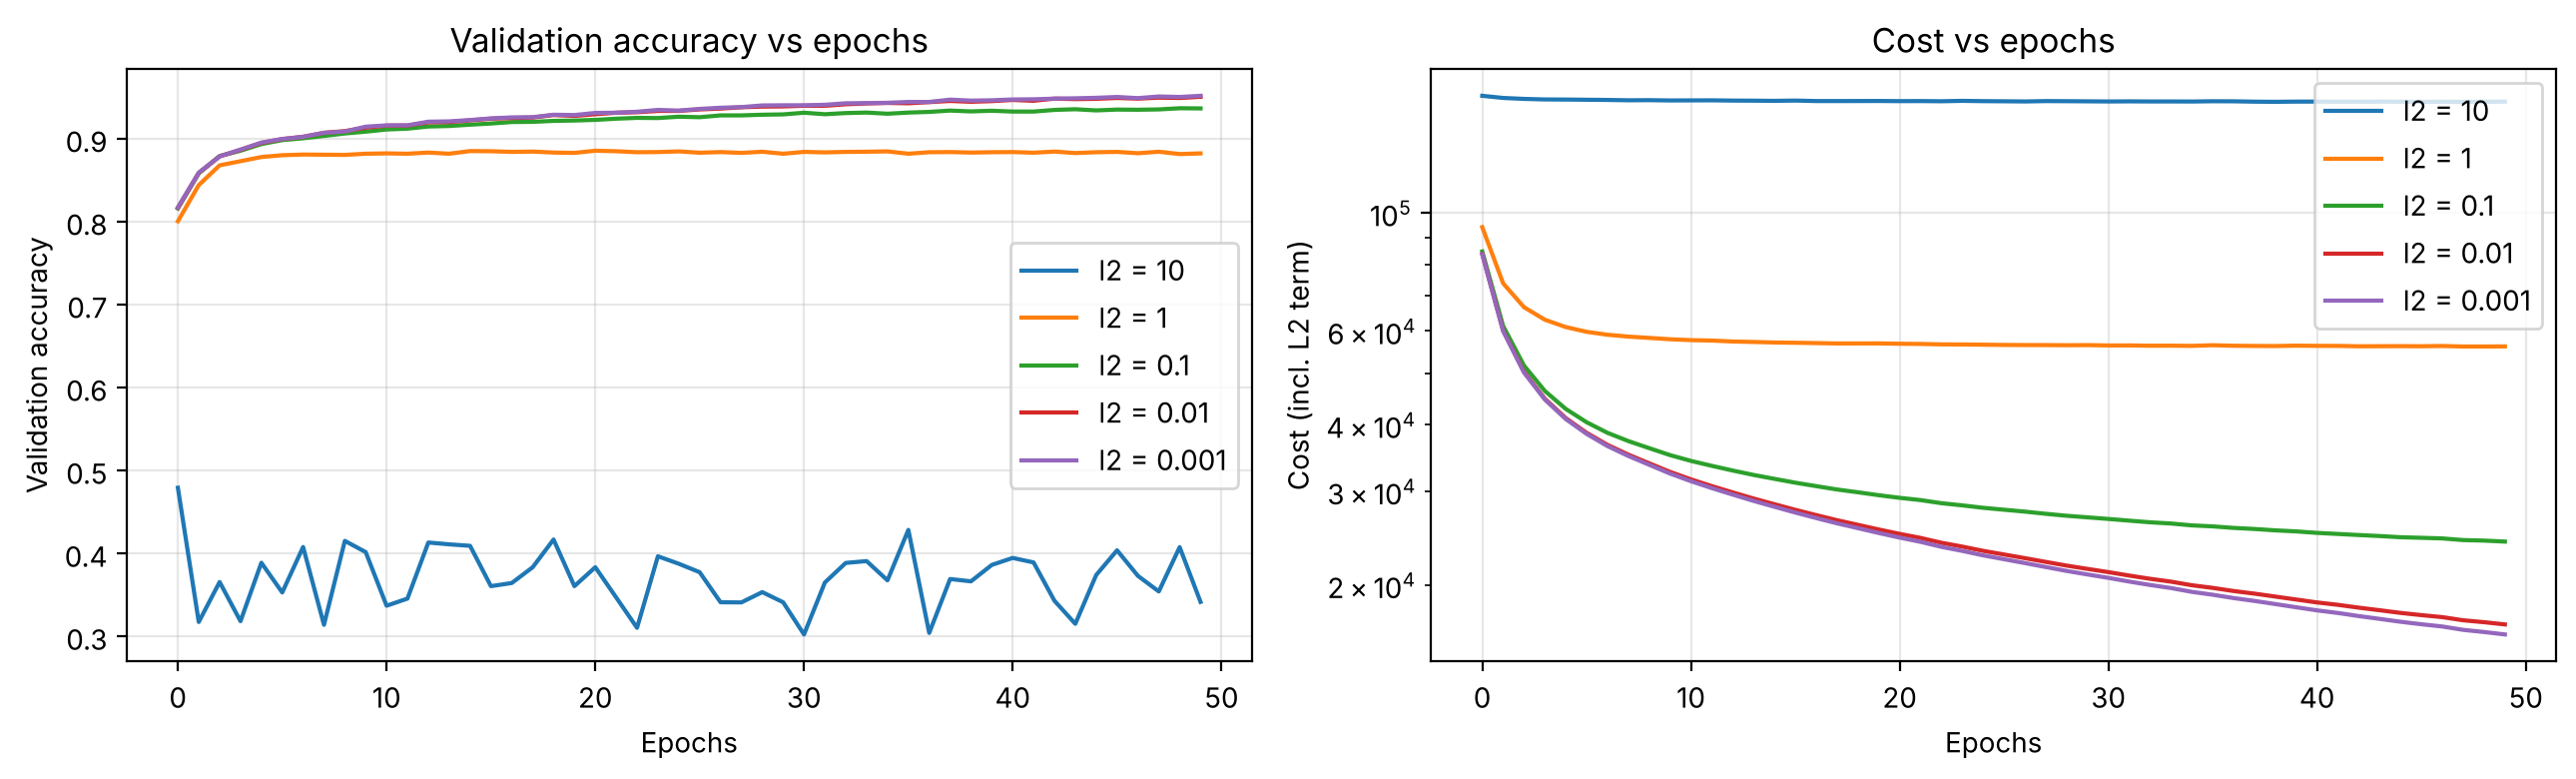

Selected l2 (highest validation accuracy): 0.001


In [16]:
# Part A - validation accuracy curves for each l2
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for l2 in l2_values:
    axes[0].plot(screen_models[l2].eval_['valid_acc'], label=f"l2 = {l2}")
    axes[1].plot(screen_models[l2].eval_['cost'], label=f"l2 = {l2}")
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Validation accuracy"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Epochs"); axes[1].set_ylabel("Cost (incl. L2 term)"); axes[1].set_yscale('log'); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[0].set_title("Validation accuracy vs epochs"); axes[1].set_title("Cost vs epochs")
plt.tight_layout(); plt.show()

# Choose l2 by VALIDATION accuracy (the test set is not used for choosing)
best_l2 = screen_df.loc[screen_df["valid_acc (%)"].idxmax(), "l2"]
print("Selected l2 (highest validation accuracy):", best_l2)

001/200 | Cost: 83622.48 | Train/Valid Acc.: 81.03%/81.68% 


002/200 | Cost: 60017.41 | Train/Valid Acc.: 85.76%/85.88% 


003/200 | Cost: 50149.86 | Train/Valid Acc.: 88.05%/87.84% 


004/200 | Cost: 44605.83 | Train/Valid Acc.: 89.06%/88.66% 


005/200 | Cost: 41003.55 | Train/Valid Acc.: 89.70%/89.50% 


006/200 | Cost: 38450.03 | Train/Valid Acc.: 90.26%/89.94% 


... (190 outputs left out)

197/200 | Cost: 6380.52 | Train/Valid Acc.: 98.73%/97.26% 


198/200 | Cost: 6357.25 | Train/Valid Acc.: 98.75%/97.28% 


199/200 | Cost: 6332.80 | Train/Valid Acc.: 98.75%/97.26% 


200/200 | Cost: 6299.86 | Train/Valid Acc.: 98.76%/97.26% 

Selected l2 = 0.001 (sigmoid, 200 epochs)
Training accuracy:   98.76%
Validation accuracy: 97.26%
Test accuracy:       97.52%


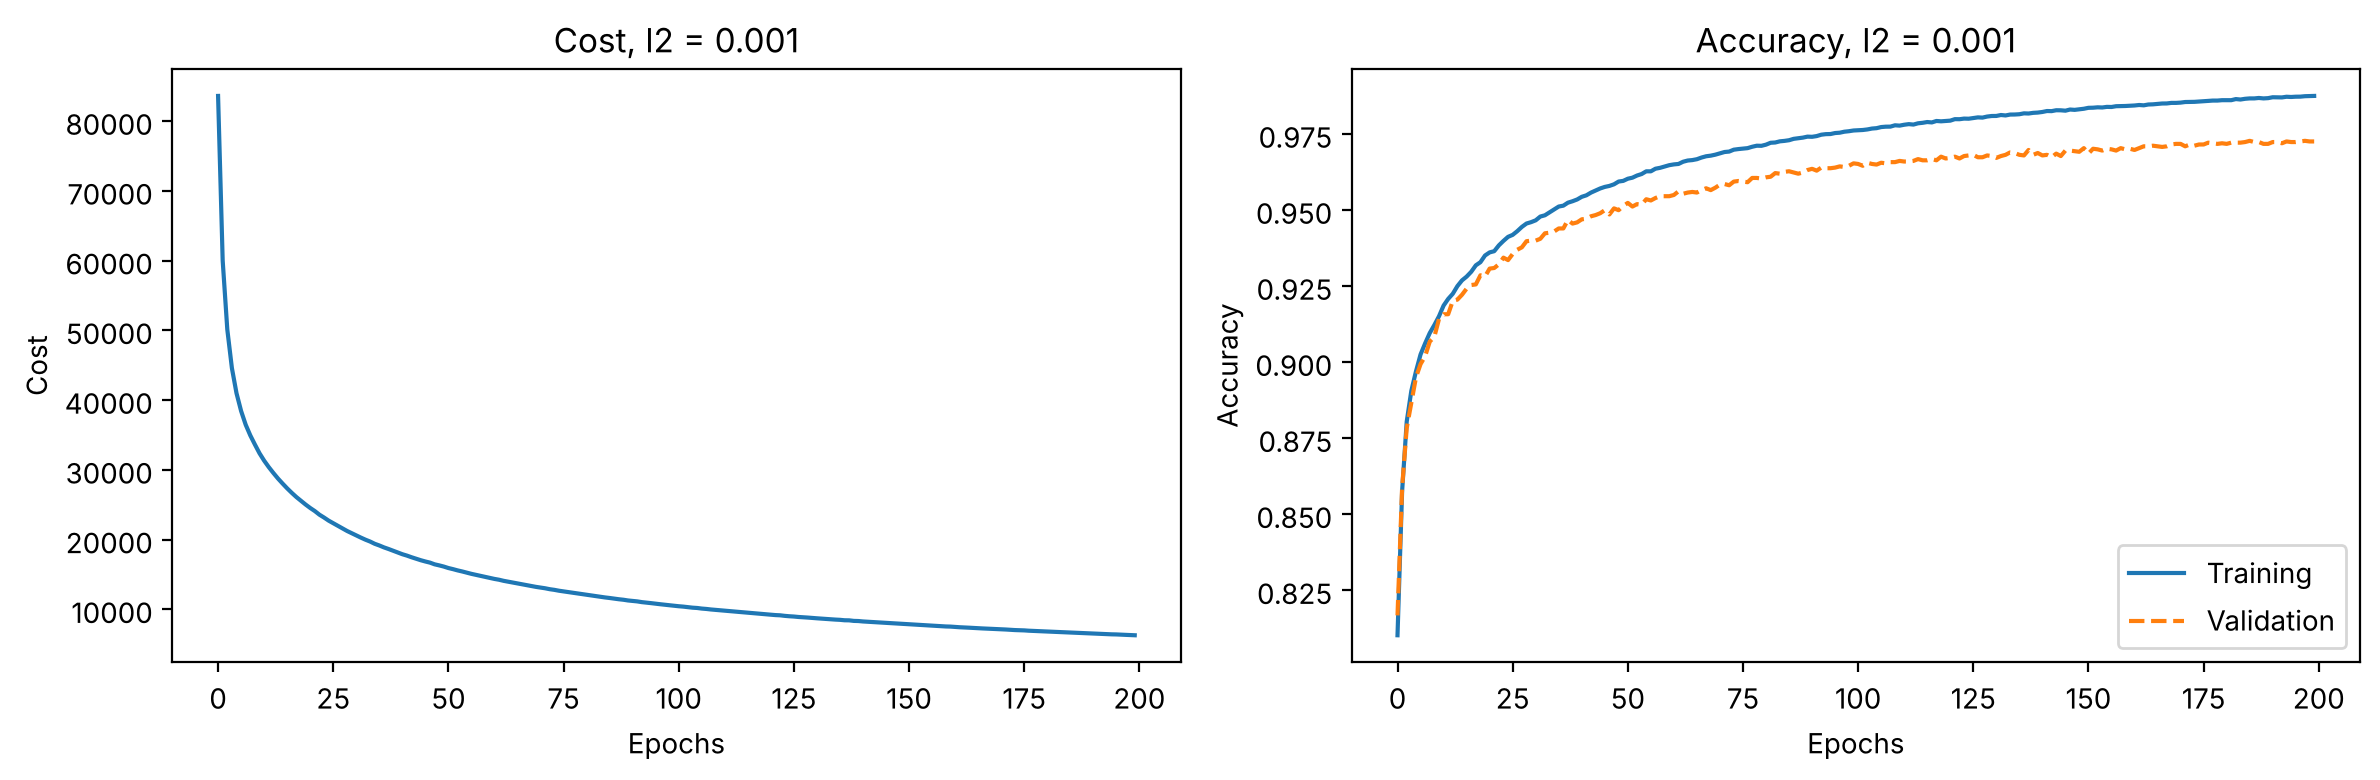

In [17]:
# Part A - retrain the selected l2 for the full 200 epochs and report the accuracies
nn_best, res_best = train_mlp(best_l2, "sigmoid", epochs=N_EPOCHS_FULL, verbose=True)
print(f"\nSelected l2 = {best_l2} (sigmoid, {N_EPOCHS_FULL} epochs)")
print(f"Training accuracy:   {res_best['train_acc (%)']:.2f}%")
print(f"Validation accuracy: {res_best['valid_acc (%)']:.2f}%")
print(f"Test accuracy:       {res_best['test_acc (%)']:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(nn_best.epochs), nn_best.eval_['cost']); axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Cost')
axes[0].set_title(f"Cost, l2 = {best_l2}")
axes[1].plot(range(nn_best.epochs), nn_best.eval_['train_acc'], label='Training')
axes[1].plot(range(nn_best.epochs), nn_best.eval_['valid_acc'], label='Validation', linestyle='--')
axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Accuracy'); axes[1].legend(loc='lower right')
axes[1].set_title(f"Accuracy, l2 = {best_l2}")
plt.tight_layout(); plt.show()

**Part A discussion – why the accuracy changes so much with `l2`.**

The L2 term adds $\lambda \sum w^2$ to the cost. Its gradient, $\lambda w$, is added in **every mini-batch update**: `delta_w = grad + l2 * w`. So each step shrinks every weight by a factor of $(1 - \alpha\lambda)$ before the data gradient is applied. Note that the data gradient here is *summed* over the 100 samples of a mini-batch, and the L2 term is not divided by the batch size, so `l2 = 10` is a very strong penalty.

* **l2 = 10 (tutorial value): heavy underfitting.** With α = 0.0005 the weights shrink by 0.5% on every one of the 550 updates per epoch. That decay is as strong as the pull from the data, so the weights are held close to zero. The hidden sigmoids then sit near 0.5 and carry very little information, and the network cannot fit the digits. Accuracy stays around 35–40% and jumps around from epoch to epoch, because the two forces keep fighting (this is the oscillation in the tutorial's printout). Training, validation and test accuracy are all equally poor, which is the signature of **underfitting (high bias)**, not overfitting.
* **Lower l2 (1 → 0.1 → 0.01): much better.** The penalty no longer dominates, so the weights can grow enough to learn useful features. In the 50-epoch screening run, validation accuracy rises from 34.1% (l2 = 10) to 88.2% (l2 = 1), 93.6% (l2 = 0.1) and 95.0% (l2 = 0.01). Training, validation and test accuracy all rise together, which confirms that the problem at l2 = 10 was underfitting.
* **Very small l2 (0.001).** This gave the highest validation accuracy in the screening run (95.14%), so it is the value selected. The test set is only used once, for the final report. It is only 0.12 percentage points above l2 = 0.01 (95.02%), which is within run-to-run noise. Below about 0.01, the penalty hardly affects training at all, so 0.01 and 0.001 are effectively tied. With so little regularisation, overfitting becomes the risk instead. In the full 200-epoch run with l2 = 0.001 there is a small but growing gap between training and validation accuracy, but validation accuracy is still improving slowly. Even smaller values (or 0) would give no further benefit.

**Selected l2 = 0.001 (sigmoid, 200 epochs): training 98.76%, validation 97.26%, test 97.52%.** That compares with 37.29% test accuracy for the tutorial's l2 = 10.

*(The training/validation split in the tutorial is shuffled without a fixed seed, so the exact numbers change slightly each time the notebook is re-run, and l2 = 0.01 may win the screening instead of 0.001. The conclusions do not change.)*

### Task 1 – Part B: tanh and ReLU in the hidden layer

The activation is selected in the class constructor. `tanh` and `relu` branches were added next to the existing `sigmoid` one, together with their derivatives written in terms of the activation `a_h`: tanh′ = 1 − a_h², ReLU′ = 1 if a_h > 0, else 0. The output layer stays sigmoid, as required. All other hyper-parameters, including the selected `l2`, are the same.

In [18]:
# Part B - tanh
nn_tanh, res_tanh = train_mlp(best_l2, "tanh", epochs=N_EPOCHS_FULL, verbose=True)

001/200 | Cost: 46103.54 | Train/Valid Acc.: 88.62%/88.78% 


002/200 | Cost: 35787.72 | Train/Valid Acc.: 90.82%/90.34% 


003/200 | Cost: 31209.58 | Train/Valid Acc.: 91.99%/91.54% 


004/200 | Cost: 28024.17 | Train/Valid Acc.: 92.80%/92.08% 


005/200 | Cost: 25638.85 | Train/Valid Acc.: 93.42%/92.84% 


006/200 | Cost: 23804.06 | Train/Valid Acc.: 93.93%/93.18% 


... (190 outputs left out)

197/200 | Cost: 1503.59 | Train/Valid Acc.: 99.95%/97.60% 


198/200 | Cost: 1495.97 | Train/Valid Acc.: 99.95%/97.62% 


199/200 | Cost: 1478.30 | Train/Valid Acc.: 99.95%/97.50% 


200/200 | Cost: 1472.36 | Train/Valid Acc.: 99.95%/97.56% 


In [19]:
# Part B - relu
nn_relu, res_relu = train_mlp(best_l2, "relu", epochs=N_EPOCHS_FULL, verbose=True)

001/200 | Cost: 41225.30 | Train/Valid Acc.: 89.77%/89.48% 


002/200 | Cost: 31640.88 | Train/Valid Acc.: 91.93%/91.30% 


003/200 | Cost: 27084.37 | Train/Valid Acc.: 93.12%/92.40% 


004/200 | Cost: 24005.83 | Train/Valid Acc.: 93.81%/93.20% 


005/200 | Cost: 21648.87 | Train/Valid Acc.: 94.57%/93.92% 


006/200 | Cost: 19940.42 | Train/Valid Acc.: 94.95%/94.30% 


... (190 outputs left out)

197/200 | Cost: 843.85 | Train/Valid Acc.: 99.98%/97.68% 


198/200 | Cost: 830.56 | Train/Valid Acc.: 99.99%/97.68% 


199/200 | Cost: 824.82 | Train/Valid Acc.: 99.99%/97.62% 


200/200 | Cost: 826.41 | Train/Valid Acc.: 99.99%/97.72% 


,activation,l2,epochs,train_acc (%),valid_acc (%),test_acc (%),time (s)
0,sigmoid,0.0,200,98.76,97.26,97.52,478
1,tanh,0.0,200,99.95,97.56,97.65,441
2,relu,0.0,200,99.99,97.72,98.11,423


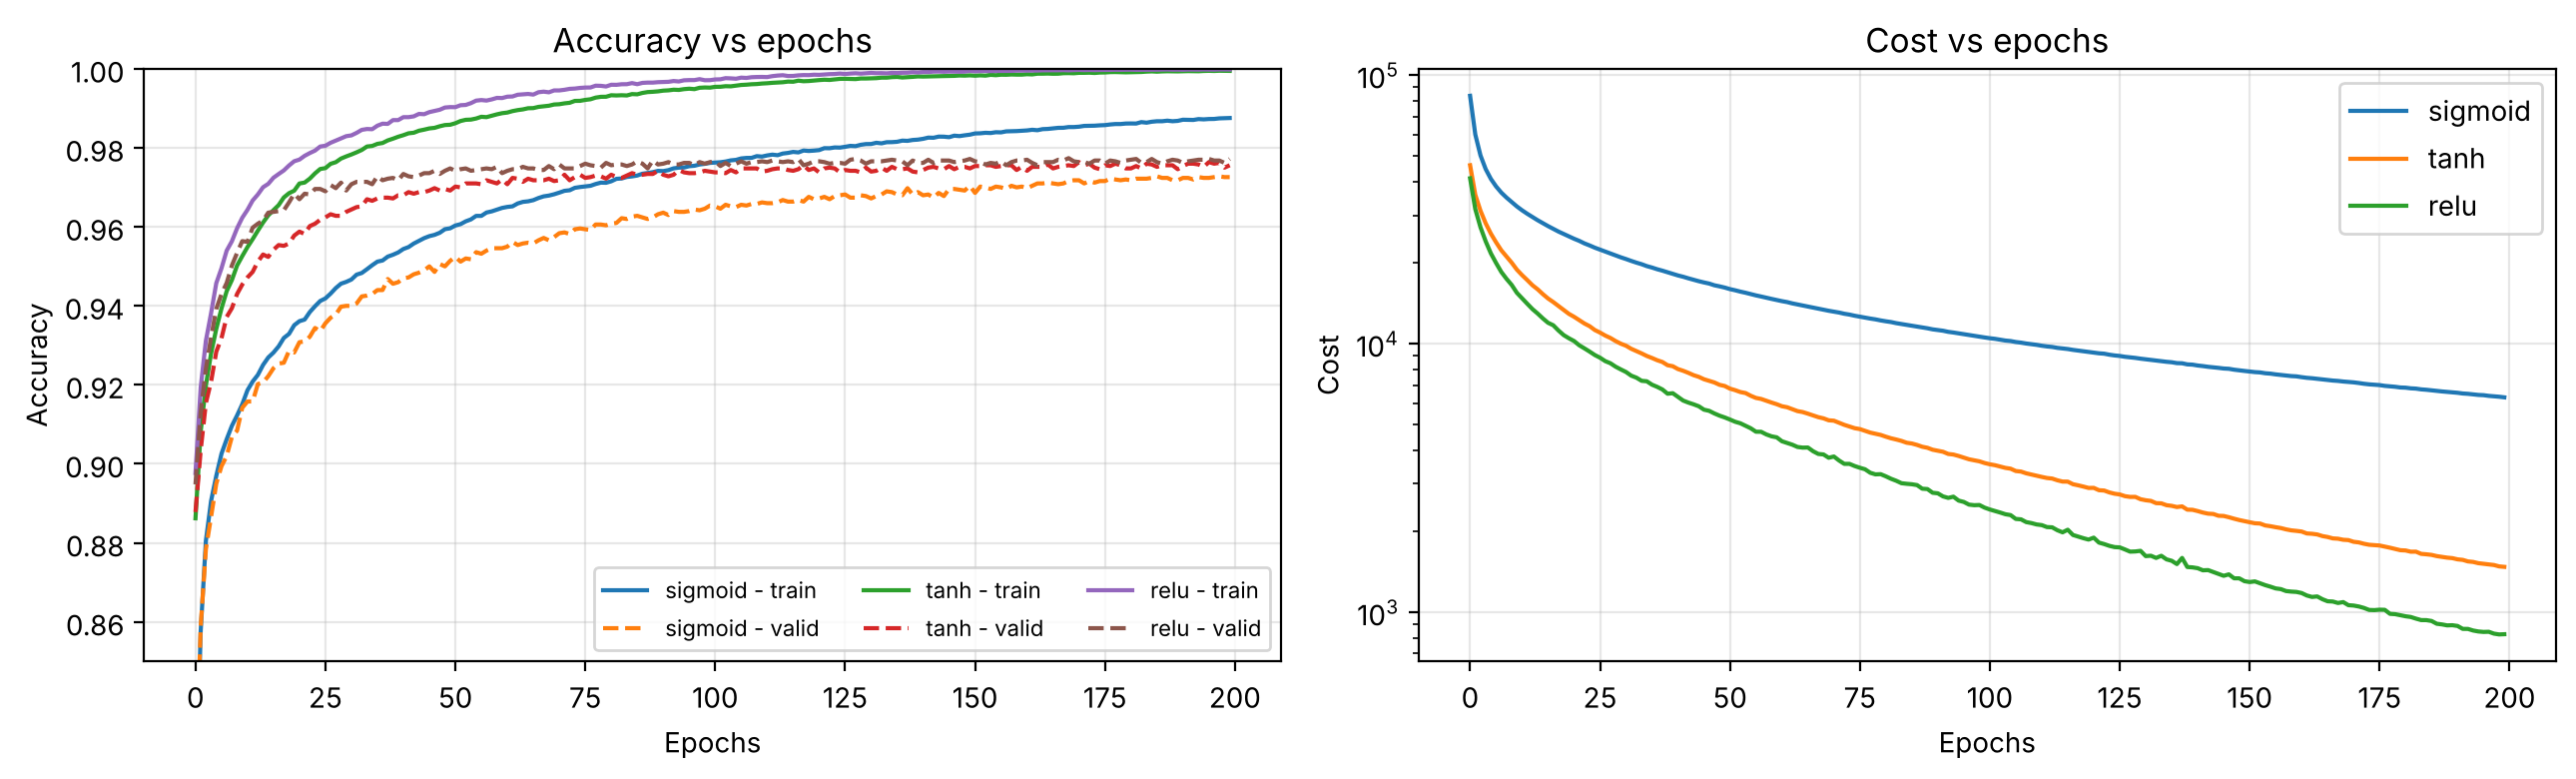

In [20]:
# Part B - comparison of activation functions
act_df = pd.DataFrame([res_best, res_tanh, res_relu])
display(act_df.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, m in [("sigmoid", nn_best), ("tanh", nn_tanh), ("relu", nn_relu)]:
    axes[0].plot(m.eval_['train_acc'], label=f"{name} - train")
    axes[0].plot(m.eval_['valid_acc'], linestyle='--', label=f"{name} - valid")
    axes[1].plot(m.eval_['cost'], label=name)
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0.85, 1.0)
axes[0].legend(fontsize=8, ncol=3); axes[0].grid(alpha=0.3); axes[0].set_title("Accuracy vs epochs")
axes[1].set_xlabel("Epochs"); axes[1].set_ylabel("Cost"); axes[1].set_yscale('log')
axes[1].legend(); axes[1].grid(alpha=0.3); axes[1].set_title("Cost vs epochs")
plt.tight_layout(); plt.show()

**Part B discussion.**

* **Faster, better training with tanh and ReLU.** Both reach a higher training accuracy than sigmoid within the same number of epochs, and also a somewhat higher validation and test accuracy.
  * **tanh** is zero-centred (output in [−1, 1]), so the inputs to the output layer are not all positive. That gives better-conditioned gradients, and its maximum derivative is 1 rather than sigmoid's 0.25, so the error signal back-propagated to the first layer is up to 4× larger.
  * **ReLU** has a derivative of exactly 1 for active units, so gradients do not shrink as they flow back through the hidden layer, and it gives sparse activations. Both effects speed up learning.
* **Sigmoid** saturates (its derivative is close to 0 for large |z|) and at most 0.25, so with the same small learning rate it learns more slowly.
* **Generalisation gap.** Because tanh and ReLU fit the training data faster, their training accuracy gets close to 100% and the **gap between training and validation accuracy is larger** than for sigmoid. That means they are starting to overfit, and with these activations a slightly larger `l2` or early stopping may be worthwhile.
* **ReLU risks.** Units can "die" if their input stays negative (derivative 0, so they never recover). With this small learning rate and small initial weights, that is not a noticeable problem here.

**Results (l2 = 0.001, 200 epochs):**

| Hidden activation | Training | Validation | Test |
|---|---|---|---|
| sigmoid | 98.76% | 97.26% | 97.52% |
| tanh | 99.95% | 97.56% | 97.65% |
| ReLU | 99.99% | 97.72% | 98.11% |

ReLU gives the best test accuracy, followed by tanh, then sigmoid. The training-validation gap is about 1.5 points for sigmoid and about 2.3–2.4 points for tanh and ReLU, which shows the faster-learning activations overfit slightly more.

## Task 2 [40 marks]

For this task, use the optimized `l2` value obtained from Task 1 and the `sigmoid` activation function for your model. This task focuses on evaluating the model's performance and reporting various metrics.

### Part A: Confusion Matrix

Write code to display the confusion matrix of the test data. Include both the code and the generated figure in your report.

### Part B: Precision, Recall, and F1-Score Calculation

Write code to estimate precision, recall, and F1-score for the test data, considering each class separately. Include both the code and the results in your report.

Reminder: The formulas for these metrics are as follows:

- Accuracy:
  \begin{equation}
      Accuracy = \frac{TN + TP}{TN + TP + FN + FP}
  \end{equation}

- Precision:
  \begin{equation}
      Precision = \frac{TP}{TP + FP}
  \end{equation}

- Recall:
  \begin{equation}
      Recall = \frac{TP}{TP + FN}
  \end{equation}

- F1-Score:
  \begin{equation}
      F1\text{-}score = \frac{2 \cdot (Precision \cdot Recall)}{Precision + Recall}
  \end{equation}

Where:
- TN = True Negative
- TP = True Positive
- FN = False Negative
- FP = False Positive

For reference and a useful diagram, you can visit the Wikipedia page on [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall).

Please ensure you provide both the code and the calculated results in your report for a comprehensive evaluation of the model's performance.


Confusion matrix (rows = true, columns = predicted):
 [[ 968    0    1    1    0    3    4    2    1    0]
 [   0 1125    1    1    0    1    3    1    3    0]
 [   5    1 1003    3    3    1    3    7    4    2]
 [   1    0    3  992    0    1    1    7    2    3]
 [   1    0    3    0  959    0    4    0    2   13]
 [   6    1    0    9    0  861    6    1    4    4]
 [   8    2    1    0    2    5  937    0    3    0]
 [   2    9   11    3    2    0    0  992    1    8]
 [   3    1    4    5    4    4    3    3  944    3]
 [   3    5    0    7   11    4    1    7    0  971]]
Overall test accuracy = trace / total = 9752 / 10000 = 97.52%


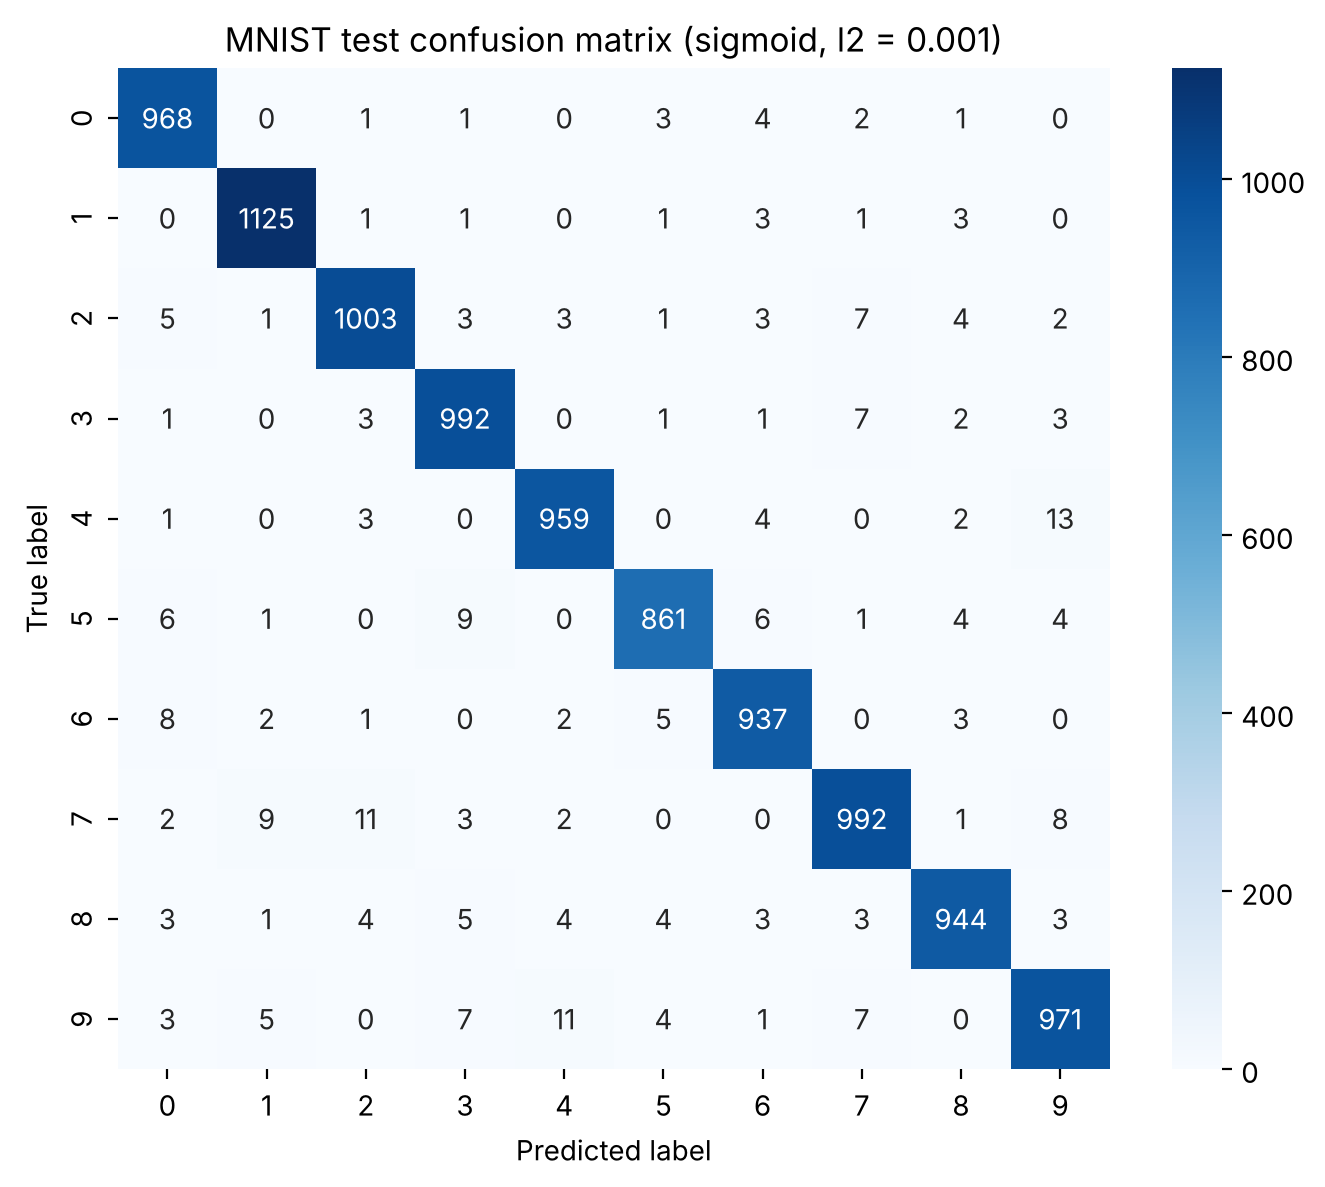

In [21]:
# Task 2 - Part A: confusion matrix of the test data (selected l2, sigmoid)
import seaborn as sns

y_test_pred_best = nn_best.predict(X_test)
n_classes = 10

def confusion_matrix_np(true, pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(true, pred):
        cm[t, p] += 1               # rows = true class, columns = predicted class
    return cm

cm = confusion_matrix_np(y_test, y_test_pred_best, n_classes)
print("Confusion matrix (rows = true, columns = predicted):\n", cm)
print(f"Overall test accuracy = trace / total = {cm.trace()} / {cm.sum()} = {100 * cm.trace() / cm.sum():.2f}%")

plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=range(n_classes), yticklabels=range(n_classes))
plt.xlabel('Predicted label'); plt.ylabel('True label')
plt.title(f"MNIST test confusion matrix (sigmoid, l2 = {best_l2})")
plt.show()

In [22]:
# Task 2 - Part B: precision, recall and F1-score per class (one-vs-rest)
# For class k:  TP = cm[k,k],  FP = column k minus TP,  FN = row k minus TP,  TN = everything else
rows = []
for k in range(n_classes):
    TP = cm[k, k]
    FP = cm[:, k].sum() - TP
    FN = cm[k, :].sum() - TP
    TN = cm.sum() - TP - FP - FN
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    accuracy_k = (TP + TN) / (TP + TN + FP + FN)
    rows.append([k, TP, FP, FN, TN, precision, recall, f1, accuracy_k, TP + FN])

metrics = pd.DataFrame(rows, columns=["class", "TP", "FP", "FN", "TN", "precision", "recall",
                                      "f1-score", "one-vs-rest accuracy", "support"])
macro = metrics[["precision", "recall", "f1-score"]].mean()
weighted = (metrics[["precision", "recall", "f1-score"]].mul(metrics["support"], axis=0).sum()
            / metrics["support"].sum())
display(metrics.round(4))
print("Macro average    - precision: %.4f  recall: %.4f  f1: %.4f" % tuple(macro))
print("Weighted average - precision: %.4f  recall: %.4f  f1: %.4f" % tuple(weighted))

,class,TP,FP,FN,TN,precision,recall,f1-score,one-vs-rest accuracy,support
0,0,968,29,12,8991,0.9709,0.9878,0.9793,0.9959,980
1,1,1125,19,10,8846,0.9834,0.9912,0.9873,0.9971,1135
2,2,1003,24,29,8944,0.9766,0.9719,0.9743,0.9947,1032
3,3,992,29,18,8961,0.9716,0.9822,0.9769,0.9953,1010
4,4,959,22,23,8996,0.9776,0.9766,0.9771,0.9955,982
5,5,861,19,31,9089,0.9784,0.9652,0.9718,0.9950,892
6,6,937,25,21,9017,0.9740,0.9781,0.9760,0.9954,958
7,7,992,28,36,8944,0.9725,0.9650,0.9688,0.9936,1028
8,8,944,20,30,9006,0.9793,0.9692,0.9742,0.9950,974
9,9,971,33,38,8958,0.9671,0.9623,0.9647,0.9929,1009


Macro average    - precision: 0.9751  recall: 0.9749  f1: 0.9750
Weighted average - precision: 0.9752  recall: 0.9752  f1: 0.9752


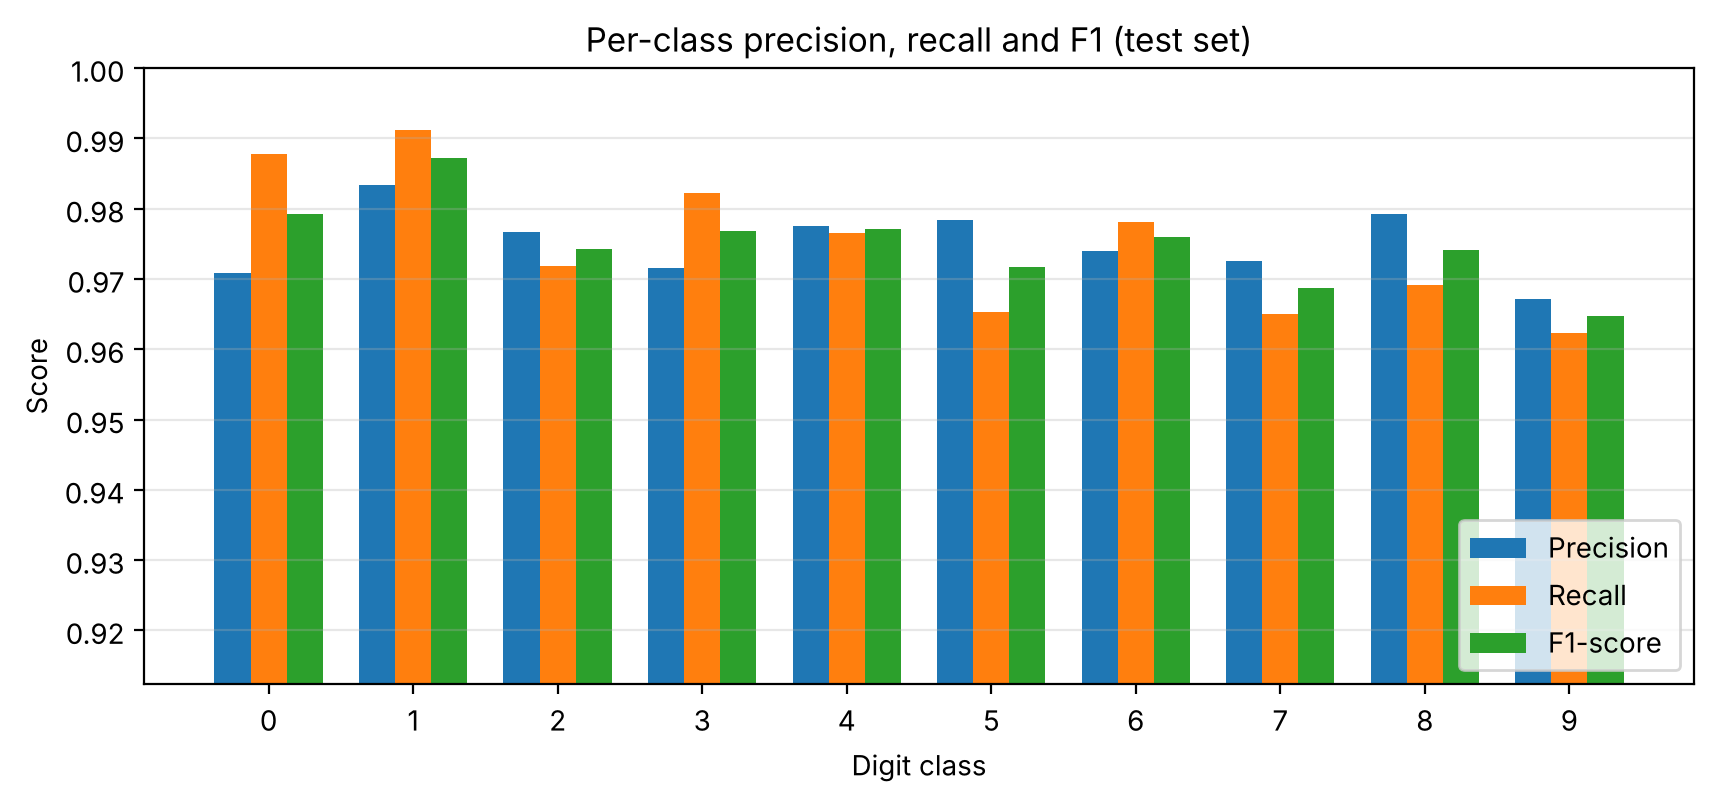

Best class (F1): 1 (0.9873) | Worst class (F1): 9 (0.9647)
Most common confusion: true 4 predicted as 9 (13 times)


In [23]:
# Task 2 - Part B (continued): visual comparison per class
x_pos = np.arange(n_classes)
plt.figure(figsize=(10, 4))
plt.bar(x_pos - 0.25, metrics["precision"], 0.25, label="Precision")
plt.bar(x_pos, metrics["recall"], 0.25, label="Recall")
plt.bar(x_pos + 0.25, metrics["f1-score"], 0.25, label="F1-score")
plt.xticks(x_pos); plt.xlabel("Digit class"); plt.ylabel("Score")
plt.ylim(max(0, metrics[["precision", "recall", "f1-score"]].values.min() - 0.05), 1.0)
plt.title("Per-class precision, recall and F1 (test set)"); plt.legend(loc='lower right'); plt.grid(axis='y', alpha=0.3)
plt.show()

worst = metrics.sort_values("f1-score").iloc[0]
best = metrics.sort_values("f1-score").iloc[-1]
off = cm.copy(); np.fill_diagonal(off, 0)
t, p = np.unravel_index(off.argmax(), off.shape)
print(f"Best class (F1): {int(best['class'])} ({best['f1-score']:.4f}) | Worst class (F1): {int(worst['class'])} ({worst['f1-score']:.4f})")
print(f"Most common confusion: true {t} predicted as {p} ({off[t, p]} times)")

**Task 2 notes.**
* The confusion matrix is built directly with NumPy (rows = true digit, columns = predicted digit) and drawn with Seaborn. The diagonal holds the correct predictions, so its sum divided by the total is the overall accuracy.
* For a multi-class problem, each class is treated as **one-vs-rest**. For class $k$: TP is the diagonal entry, FP is the rest of column $k$ (other digits predicted as $k$), FN is the rest of row $k$ ($k$ predicted as something else), and TN is everything else.
* **Precision** answers "when the model says $k$, how often is it right?" **Recall** answers "of all the real $k$s, how many did it find?" **F1** is their harmonic mean, so it is only high when both are high.
* Digits with simple, distinctive shapes score highest: **1** has the best F1 (0.987), followed by **0** (0.979). Digits that share strokes with others score lowest: **9** has the worst F1 (0.965), then **7** (0.969) and **5** (0.972). The most common single confusion is a true **4 predicted as 9** (13 times). Other frequent ones are 7 → 2 (11), 9 → 4 (11) and 5 → 3 (9).
* The "one-vs-rest accuracy" column is always very high (typically 97–99%) because TN dominates: 90% of samples are not class $k$. That is why precision, recall and F1 are more informative than accuracy for each individual class.